I collected apartment listings from reklama5.mk with my own Python scraper.
**Question:** how do prices differ between Bitola and Ohrid?

In [19]:
import pandas as pd

df = pd.read_excel("/kaggle/input/datasets/dejanlazarovski/reklama5/oglasi.xlsx")
df.head(10)


,grad,naslov,cena,m2,sobi,link
0,Битола,stan vo karpos - se prodava star ednosoben stan,28000,33.0,2.0,https://www.reklama5.mk/AdDetails?ad=5862737
1,Битола,Se prodava stan,56000,NaN,2.5,https://www.reklama5.mk/AdDetails?ad=5795659
2,Битола,Stan vo Bitola,59000,50.0,3.0,https://www.reklama5.mk/AdDetails?ad=5812932
3,Битола,SE Prodava EDNOSOBEN STAN,55000,33.0,2.0,https://www.reklama5.mk/AdDetails?ad=5737396
4,Битола,Се продава stan,54000,45.0,2.5,https://www.reklama5.mk/AdDetails?ad=5721559
5,Битола,СЕ ПРОДАВА ДВОСОБЕН СТАН ВО БЛИЗИНА НА ЗЕЛЕНОТ...,55000,38.0,2.0,https://www.reklama5.mk/AdDetails?ad=5828001
6,Битола,СЕ ПРОДАВА ГАРСОЊЕРА НАСПРОТИ ГРАДИНКАТА “ПРОЛ...,49000,30.0,2.0,https://www.reklama5.mk/AdDetails?ad=5787588
7,Битола,СЕ ПРОДАВА СТАН НА ПРИЗЕМЈЕ ВО БРУСНИЧКА НАСЕЛБА,54500,66.0,2.0,https://www.reklama5.mk/AdDetails?ad=5580503
8,Битола,ВСЕЛИВ ОДРЖАН СТАН 40М2 (33+3.5+3.5),43000,40.0,2.0,https://www.reklama5.mk/AdDetails?ad=5841954
9,Битола,Се продава реновирана гарсониера,33000,22.0,1.5,https://www.reklama5.mk/AdDetails?ad=5818627


## The data
Each row is one listing: city, title, price (€), size (m²), rooms and link.
Only listings between 25,000 and 60,000 € are included (scraper filter).

In [20]:
df.describe().round(1)

,cena,m2,sobi
count,106.0,105.0,106.0
mean,48429.1,45.5,2.0
std,8384.7,18.3,0.8
min,27000.0,20.0,1.0
25%,42000.0,30.0,1.0
50%,50000.0,45.0,2.0
75%,55000.0,55.0,2.5
max,59500.0,118.0,5.0


## Prices by city


In [21]:
df.groupby("grad")["cena"].agg(["count", "mean", "median", "min", "max"]).round(0)

,count,mean,median,min,max
grad,,,,,
Битола,43,46119.0,45600.0,27000,59500
Охрид,63,50006.0,52000.0,29000,58500


Only one listing is missing a value (m²). All other columns are complete.


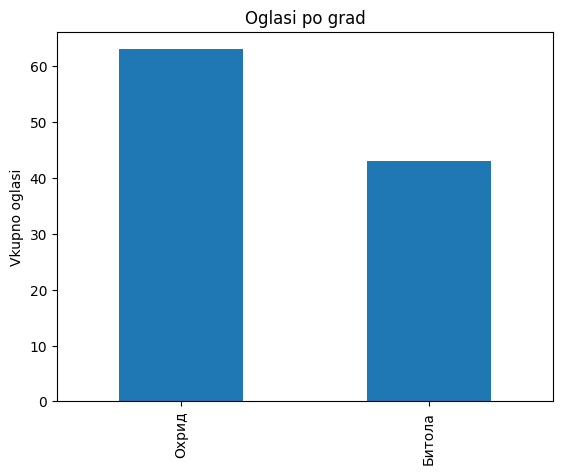

In [22]:
grafik = df.value_counts("grad").plot(kind = "bar", title="Oglasi po grad")
grafik.set_ylabel("Vkupno oglasi")
grafik.set_xlabel("");

## Data cleaning
One listing has no m², so I remove it and calculate the price per m².

In [23]:
cisti = df.dropna(subset=["m2"]).copy()
cisti["cena_m2"] = cisti["cena"] / cisti["m2"]


cisti[["grad", "cena", "m2", "cena_m2"]].head().round(0)

,grad,cena,m2,cena_m2
0,Битола,28000,33.0,848.0
2,Битола,59000,50.0,1180.0
3,Битола,55000,33.0,1667.0
4,Битола,54000,45.0,1200.0
5,Битола,55000,38.0,1447.0


## Price per m² by city

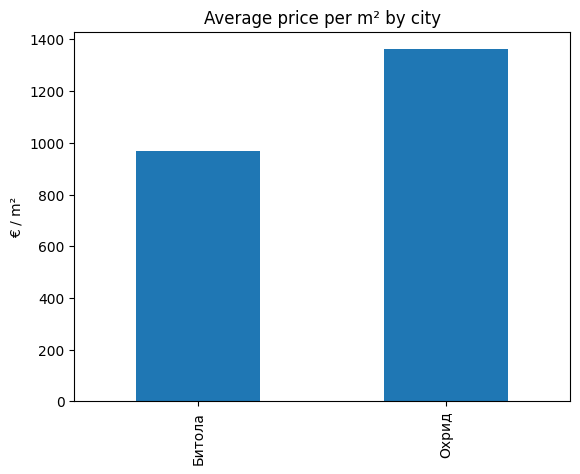

In [24]:
grafik = cisti.groupby("grad")["cena_m2"].mean().plot(kind="bar", title = "Average price per m² by city")
grafik.set_ylabel("€ / m²")
grafik.set_xlabel("");